COU 07506 – Digital Signal Processing (DSP)
Week 04: Z-Transform Laboratory, Poles, Zeros and Stability
Your lab details are filled in:
Name: SALIMIN BURUHANI SHECHONGE
Registration No.: 240242411437
Class: BEng24coe-2
Group: 1
Date: 23/11/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 4.1 — A pole-zero plotting function

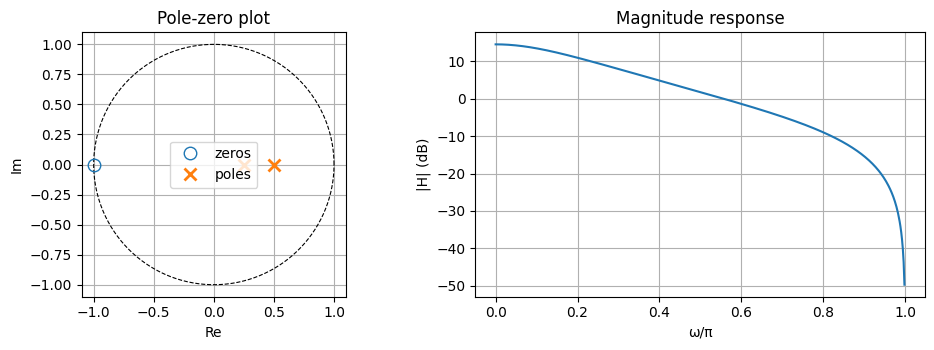

poles: [0.5  0.25]  stable: True


In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)             # zeros, poles, gain
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)      # unit circle
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend()
    ax.set_xlabel("Re"); ax.set_ylabel("Im"); ax.grid(True)
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π"); ax2.set_ylabel("|H| (dB)")
ax2.set_title("Magnitude response"); ax2.grid(True)
plt.tight_layout(); plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

## Task 4.2 — Inverse z-transform with residuez

In [3]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real     # sum of r_i * p_i^n
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print(np.allclose(x_pf, x_lf))

residues [-1.  2.] poles [0.25 0.5 ]
True


In [4]:
b, a = [1, 1], [1, -0.75, 0.125]
r2, p2, k2 = signal.residuez(b, a)
print("residues", r2, "poles", p2)

h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_lf = signal.lfilter(b, a, impulse)
h_cf = 6*(0.5)**n - 5*(0.25)**n

print("partial fractions = lfilter    :", np.allclose(h_pf, h_lf))
print("partial fractions = closed form:", np.allclose(h_pf, h_cf))

residues [-5.  6.] poles [0.25 0.5 ]
partial fractions = lfilter    : True
partial fractions = closed form: True


## Task 4.3 — Pole position and the impulse response

r = 0.50: peak |H| =      1.89, max|h(n)| =      1.00, stable = True
r = 0.80: peak |H| =      3.93, max|h(n)| =      1.13, stable = True
r = 0.95: peak |H| =     14.50, max|h(n)| =      1.34, stable = True
r = 1.00: peak |H| = 98555799216545392.00, max|h(n)| =      1.41, stable = False
r = 1.05: peak |H| =     13.79, max|h(n)| =      8.60, stable = False


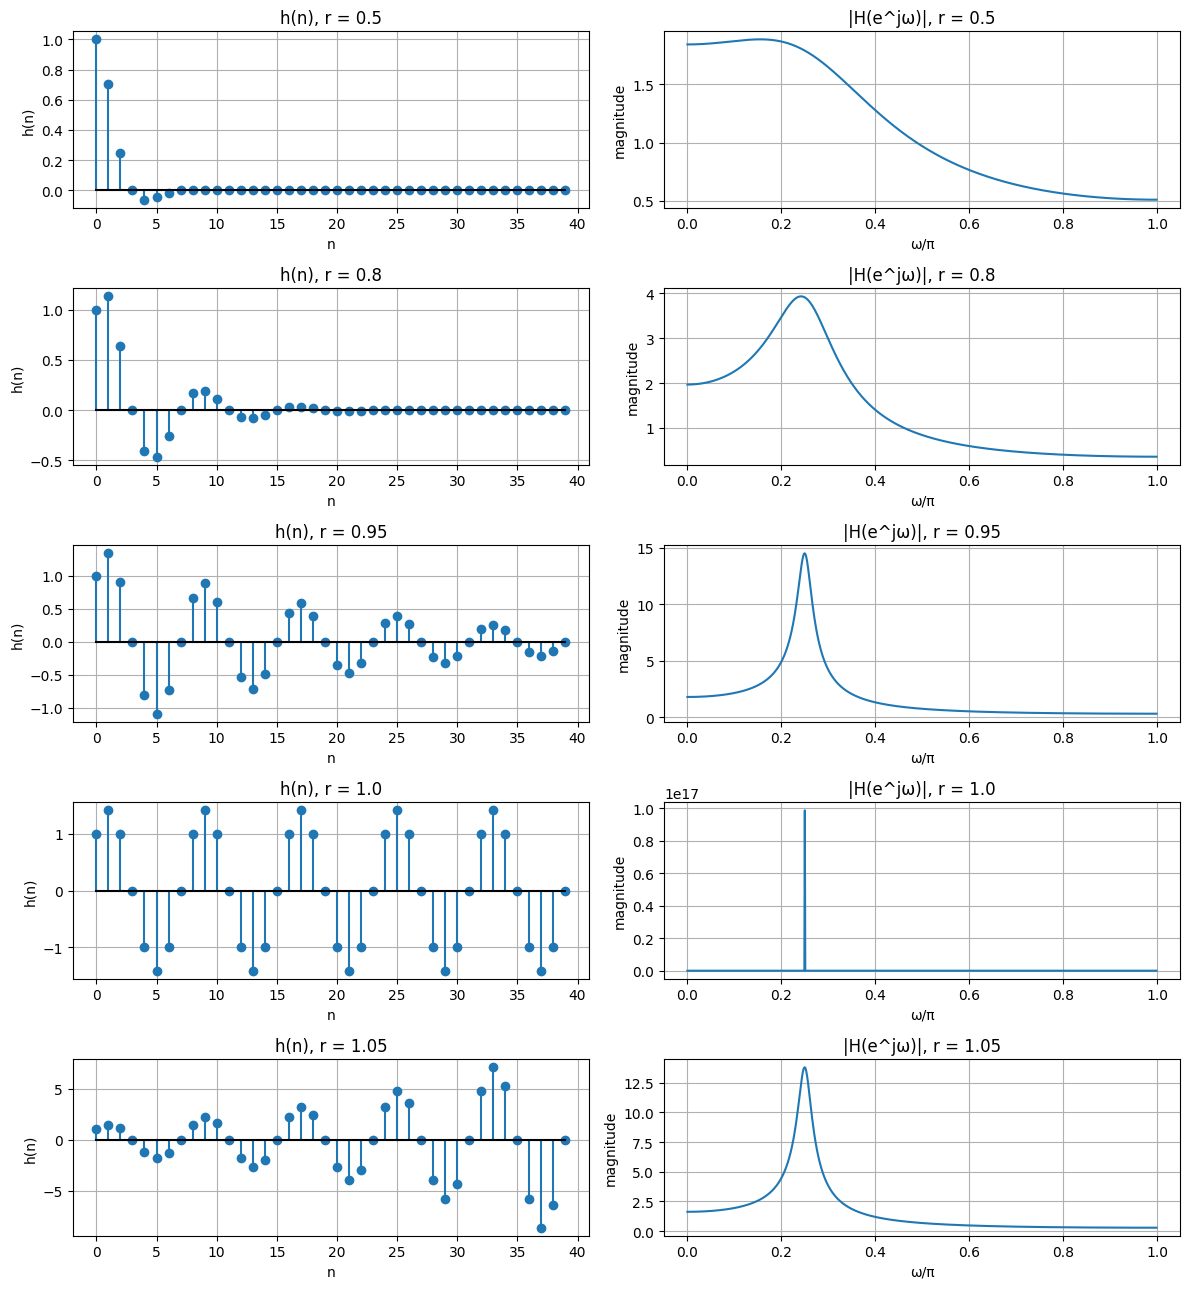

In [5]:
n = np.arange(40)
impulse = np.zeros(40); impulse[0] = 1
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi/4

fig, axes = plt.subplots(len(radii), 2, figsize=(12, 13))
for row, r in enumerate(radii):
    a = [1, -2*r*np.cos(theta), r**2]
    h = signal.lfilter([1], a, impulse)
    w, H = signal.freqz([1], a, worN=1024)

    axes[row, 0].stem(n, h, basefmt="k-")
    axes[row, 0].set_title(f"h(n), r = {r}")
    axes[row, 0].set_xlabel("n"); axes[row, 0].set_ylabel("h(n)")

    axes[row, 1].plot(w/np.pi, np.abs(H))
    axes[row, 1].set_title(f"|H(e^jω)|, r = {r}")
    axes[row, 1].set_xlabel("ω/π"); axes[row, 1].set_ylabel("magnitude")

    for ax in axes[row]:
        ax.grid(True)
    stable = np.all(np.abs(np.roots(a)) < 1)
    print(f"r = {r:4.2f}: peak |H| = {np.abs(H).max():9.2f}, "
          f"max|h(n)| = {np.abs(h).max():9.2f}, stable = {stable}")
plt.tight_layout(); plt.show()

## Task 4.4 — Stability of given systems

(a) H1: poles = [0.8+0.5j 0.8-0.5j]
      max|p| = 0.9434 -> STABLE
      max|h| first 10 samples = 1.67, last 10 samples = 0.3283
(b) H2: poles = [2.  0.5]
      max|p| = 2.0000 -> UNSTABLE
      max|h| first 10 samples = 1024, last 10 samples = 1.1e+12
(c) H3: poles = [-1.   0.5]
      max|p| = 1.0000 -> MARGINAL (pole on unit circle, not BIBO stable)
      max|h| first 10 samples = 1, last 10 samples = 0.6667
(d) H4: poles = [0. 0. 0. 0.]
      max|p| = 0.0000 -> STABLE
      max|h| first 10 samples = 1, last 10 samples = 0


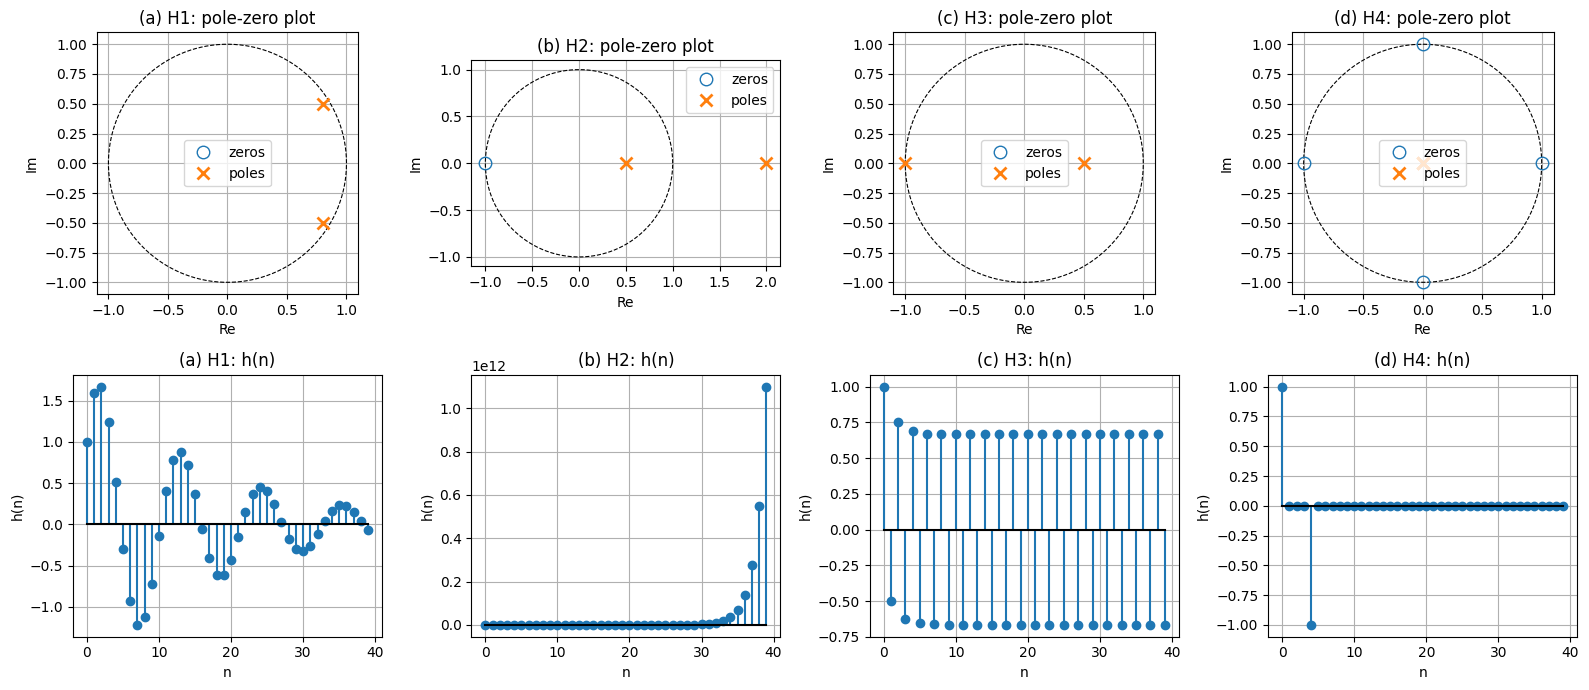

In [6]:
systems = {
    "(a) H1": ([1], [1, -1.6, 0.89]),
    "(b) H2": ([1, 1], [1, -2.5, 1]),
    "(c) H3": ([1], [1, 0.5, -0.5]),
    "(d) H4": ([1, 0, 0, 0, -1], [1, 0, 0, 0, 0]),   # 1 - z^-4, a padded so the 4 poles at z=0 appear
}

n = np.arange(40)
impulse = np.zeros(40); impulse[0] = 1

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[0, col])
    axes[0, col].set_title(f"{name}: pole-zero plot")

    h = signal.lfilter(b, a, impulse)
    axes[1, col].stem(n, h, basefmt="k-")
    axes[1, col].set_title(f"{name}: h(n)")
    axes[1, col].set_xlabel("n"); axes[1, col].set_ylabel("h(n)")
    axes[1, col].grid(True)

    rmax = np.max(np.abs(p)) if len(p) else 0.0
    if rmax < 1 - 1e-9:   verdict = "STABLE"
    elif rmax < 1 + 1e-9: verdict = "MARGINAL (pole on unit circle, not BIBO stable)"
    else:                 verdict = "UNSTABLE"
    print(f"{name}: poles = {np.round(p, 4)}")
    print(f"      max|p| = {rmax:.4f} -> {verdict}")
    print(f"      max|h| first 10 samples = {np.abs(h[:10]).max():.4g}, "
          f"last 10 samples = {np.abs(h[-10:]).max():.4g}")
plt.tight_layout(); plt.show()

## Task 4.5 — Design a resonator

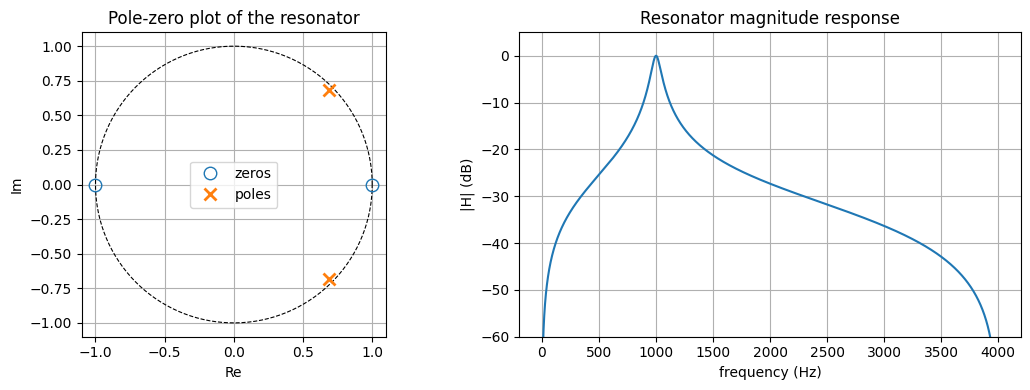

poles: [0.6859+0.6859j 0.6859-0.6859j]  |p| = [0.97 0.97]
zeros: [-1.  1.]
peak at 1001.0 Hz
-3 dB band: 962.9 to 1039.1 Hz, width = 76.2 Hz


In [7]:
fs = 8000
f0 = 1000
r = 0.97
theta = 2*np.pi*f0/fs                      # = pi/4

a = [1, -2*r*np.cos(theta), r**2]          # poles at r e^{+-j theta}
b = [1, 0, -1]                             # zeros at z = +1 and z = -1

# scale so the peak gain is 1 (0 dB)
w, H = signal.freqz(b, a, worN=4096, fs=fs)
b = np.array(b) / np.abs(H).max()
w, H = signal.freqz(b, a, worN=4096, fs=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot of the resonator")
ax2.plot(w, 20*np.log10(np.abs(H) + 1e-12))
ax2.set_ylim(-60, 5)
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("|H| (dB)")
ax2.set_title("Resonator magnitude response")
ax2.grid(True)
plt.tight_layout(); plt.show()

print("poles:", np.round(p, 4), " |p| =", np.round(np.abs(p), 3))
print("zeros:", np.round(z, 4))
print("peak at", round(w[np.argmax(np.abs(H))], 1), "Hz")

# -3 dB bandwidth
mag = np.abs(H)
band = w[mag >= mag.max()/np.sqrt(2)]
print(f"-3 dB band: {band[0]:.1f} to {band[-1]:.1f} Hz, width = {band[-1]-band[0]:.1f} Hz")

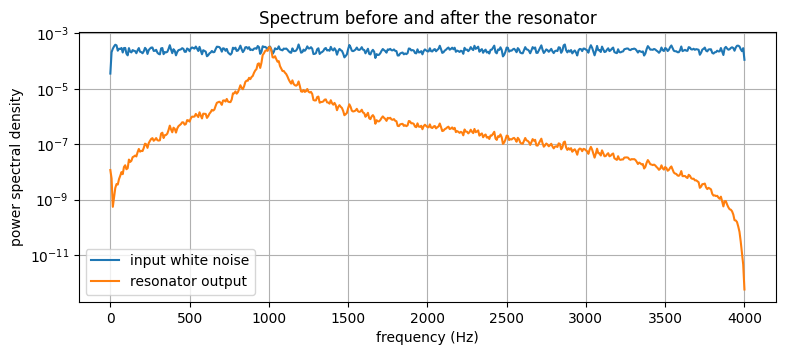

In [8]:
from IPython.display import Audio

rng = np.random.default_rng(0)
noise = rng.standard_normal(2*fs)               # 2 s of white noise
y = signal.lfilter(b, a, noise)

# spectra before and after
f1, P1 = signal.welch(noise, fs, nperseg=1024)
f2, P2 = signal.welch(y, fs, nperseg=1024)
plt.semilogy(f1, P1, label="input white noise")
plt.semilogy(f2, P2, label="resonator output")
plt.xlabel("frequency (Hz)"); plt.ylabel("power spectral density")
plt.title("Spectrum before and after the resonator")
plt.grid(True); plt.legend(); plt.show()

Audio(noise/np.max(np.abs(noise)), rate=fs)     # listen: input

In [9]:
Audio(y/np.max(np.abs(y)), rate=fs)             # listen: output